In [1]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn xgboost joblib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

try:
    df = pd.read_csv(file_name, encoding="cp1252")
except UnicodeDecodeError:
    df = pd.read_csv(file_name, encoding="latin1")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Saving APL_Logistics.csv to APL_Logistics.csv
Dataset loaded successfully!
Dataset shape: (180519, 40)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Name,Product Price,Shipping Mode
0,DEBIT,6,4,159.69,472.45,Late delivery,1,9,Cardio Equipment,Brownsville,...,5,499.95,472.45,159.69,South Asia,Maharashtra,COMPLETE,Nike Men's Free 5.0+ Running Shoe,99.99,Standard Class
1,DEBIT,4,4,48.71,167.96,Shipping on time,0,29,Shop By Sport,Littleton,...,5,199.95,167.96,48.71,Central America,Cortés,ON_HOLD,Under Armour Girls' Toddler Spine Surge Runni,39.99,Standard Class
2,DEBIT,4,4,87.36,181.99,Shipping on time,0,48,Water Sports,Littleton,...,1,199.99,181.99,87.36,Central America,Cortés,ON_HOLD,Pelican Sunstream 100 Kayak,199.99,Standard Class
3,DEBIT,6,4,-41.89,175.99,Late delivery,1,48,Water Sports,Littleton,...,1,199.99,175.99,-41.89,East of USA,Nueva York,COMPLETE,Pelican Sunstream 100 Kayak,199.99,Standard Class
4,DEBIT,6,4,10.00,40.00,Late delivery,1,24,Women's Apparel,Littleton,...,1,50.00,40.00,10.00,East of USA,Nueva York,COMPLETE,Nike Men's Dri-FIT Victory Golf Polo,50.00,Standard Class


In [3]:
# Dataset information
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nFirst 5 Records:")
display(df.head())

print("\nStatistical Summary:")
display(df.describe(include="all").T)

print("\nMissing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate Records:")
print(df.duplicated().sum())

Dataset Shape: (180519, 40)

Column Names:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Product Name', 'Product Price', 'Shipping Mode']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 40 columns):
 #   Column                         Non-Null Count   Dtype  
---  ---

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Name,Product Price,Shipping Mode
0,DEBIT,6,4,159.69,472.45,Late delivery,1,9,Cardio Equipment,Brownsville,...,5,499.95,472.45,159.69,South Asia,Maharashtra,COMPLETE,Nike Men's Free 5.0+ Running Shoe,99.99,Standard Class
1,DEBIT,4,4,48.71,167.96,Shipping on time,0,29,Shop By Sport,Littleton,...,5,199.95,167.96,48.71,Central America,Cortés,ON_HOLD,Under Armour Girls' Toddler Spine Surge Runni,39.99,Standard Class
2,DEBIT,4,4,87.36,181.99,Shipping on time,0,48,Water Sports,Littleton,...,1,199.99,181.99,87.36,Central America,Cortés,ON_HOLD,Pelican Sunstream 100 Kayak,199.99,Standard Class
3,DEBIT,6,4,-41.89,175.99,Late delivery,1,48,Water Sports,Littleton,...,1,199.99,175.99,-41.89,East of USA,Nueva York,COMPLETE,Pelican Sunstream 100 Kayak,199.99,Standard Class
4,DEBIT,6,4,10.00,40.00,Late delivery,1,24,Women's Apparel,Littleton,...,1,50.00,40.00,10.00,East of USA,Nueva York,COMPLETE,Nike Men's Dri-FIT Victory Golf Polo,50.00,Standard Class



Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Type,180519,4,DEBIT,69295,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Days for shipping (real),180519.0,NaN,NaN,NaN,3.497654,1.623722,0.0,2.0,3.0,5.0,6.0
Days for shipment (scheduled),180519.0,NaN,NaN,NaN,2.931847,1.374449,0.0,2.0,4.0,4.0,4.0
Benefit per order,180519.0,NaN,NaN,NaN,21.974989,104.433526,-4274.98,7.0,31.52,64.8,911.8
Sales per customer,180519.0,NaN,NaN,NaN,183.107607,120.043668,7.49,104.38,163.99,247.4,1939.99
Delivery Status,180519,4,Late delivery,98977,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Late_delivery_risk,180519.0,NaN,NaN,NaN,0.548291,0.497664,0.0,0.0,1.0,1.0,1.0
Category Id,180519.0,NaN,NaN,NaN,31.851451,15.640064,2.0,18.0,29.0,45.0,76.0
Category Name,180519,50,Cleats,24551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer City,180519,563,Caguas,66770,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing Values:
Customer Lname      8
Customer Zipcode    3
dtype: int64

Duplicate Records:
0


Target Variable Distribution:
Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

Target Variable Percentage:
Late_delivery_risk
1    54.83
0    45.17
Name: proportion, dtype: float64


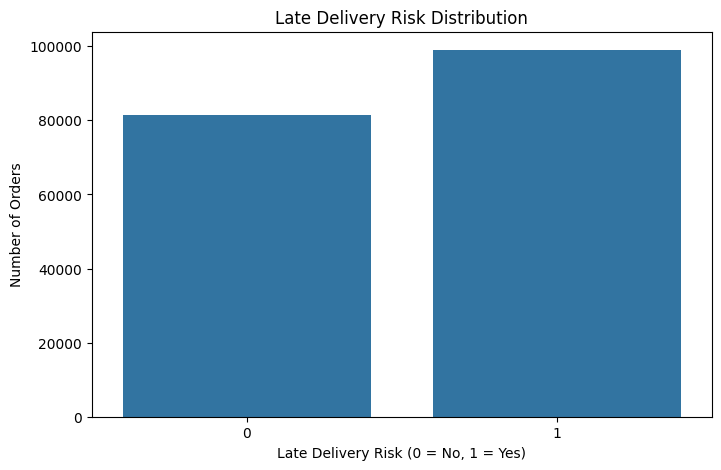

In [4]:
target = "Late_delivery_risk"

print("Target Variable Distribution:")
print(df[target].value_counts())

print("\nTarget Variable Percentage:")
print(
    (df[target].value_counts(normalize=True) * 100).round(2)
)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x=target
)

plt.title("Late Delivery Risk Distribution")
plt.xlabel("Late Delivery Risk (0 = No, 1 = Yes)")
plt.ylabel("Number of Orders")

plt.show()

In [5]:
# Target variable
target = "Late_delivery_risk"

# Numerical features
numerical_features = [
    "Days for shipment (scheduled)",
    "Category Id",
    "Department Id",
    "Latitude",
    "Longitude",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Order Item Product Price",
    "Order Item Quantity",
    "Sales",
    "Order Item Total",
    "Product Price"
]

# Categorical features
categorical_features = [
    "Type",
    "Category Name",
    "Customer Country",
    "Customer Segment",
    "Customer State",
    "Department Name",
    "Market",
    "Order Country",
    "Order Region",
    "Shipping Mode"
]

feature_columns = numerical_features + categorical_features

# Check that all selected columns exist
missing_columns = [
    col for col in feature_columns + [target]
    if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Create independent feature and target datasets
X = df[feature_columns].copy()
y = df[target].copy()

print("Selected Features:", len(feature_columns))
print("X Shape:", X.shape)
print("Y Shape:", y.shape)

print("\nExcluded leakage-sensitive columns:")
print([
    "Days for shipping (real)",
    "Delivery Status",
    "Order Status",
    "Benefit per order",
    "Sales per customer",
    "Order Profit Per Order",
    "Late_delivery_risk (target)"
])

Selected Features: 22
X Shape: (180519, 22)
Y Shape: (180519,)

Excluded leakage-sensitive columns:
['Days for shipping (real)', 'Delivery Status', 'Order Status', 'Benefit per order', 'Sales per customer', 'Order Profit Per Order', 'Late_delivery_risk (target)']


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data
X_test_processed = preprocessor.transform(X_test)

print("Training data:", X_train_processed.shape)
print("Testing data:", X_test_processed.shape)

print("Preprocessing completed successfully!")

Training data: (144415, 299)
Testing data: (36104, 299)
Preprocessing completed successfully!


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=20,
        min_samples_split=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_pipelines = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=5,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

    trained_pipelines[name] = pipeline

    print(f"{name} completed!")

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

display(comparison_df.round(4))

Logistic Regression completed!
Random Forest completed!
XGBoost completed!


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
1,Random Forest,0.6995,0.8458,0.5527,0.6685,0.7753
2,XGBoost,0.7009,0.8375,0.5638,0.6739,0.7702
0,Logistic Regression,0.6949,0.8455,0.5426,0.6610,0.7441


In [8]:
best_model_name = comparison_df.iloc[0]["Model"]

best_model = trained_pipelines[best_model_name]

print("Selected Model:", best_model_name)

# Train using the complete training dataset
best_model.fit(X_train, y_train)

print("Final model training completed!")

Selected Model: Random Forest
Final model training completed!


FINAL MODEL: Random Forest

Accuracy: 0.7017781963217372
Precision: 0.849608921242159
Recall: 0.5542028692665185
F1 Score: 0.6708245437035678
ROC-AUC: 0.7794060289988543

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.88      0.73     16308
           1       0.85      0.55      0.67     19796

    accuracy                           0.70     36104
   macro avg       0.73      0.72      0.70     36104
weighted avg       0.75      0.70      0.70     36104



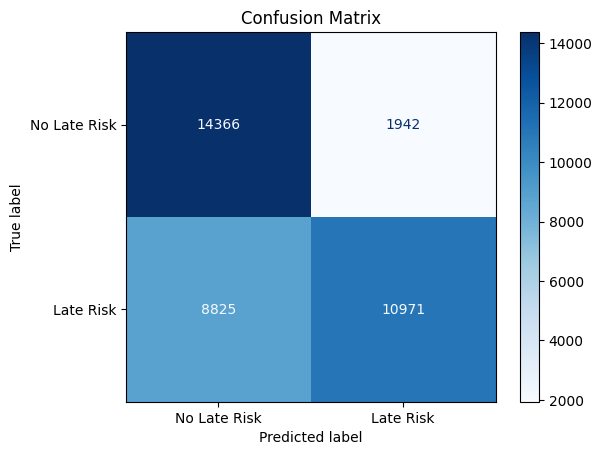

In [9]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Predictions on untouched test data
y_pred = best_model.predict(X_test)

y_probability = best_model.predict_proba(X_test)[:, 1]

# Evaluation metrics
print("FINAL MODEL:", best_model_name)

print("\nAccuracy:",
      accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(y_test, y_pred))

print("Recall:",
      recall_score(y_test, y_pred))

print("F1 Score:",
      f1_score(y_test, y_pred))

print("ROC-AUC:",
      roc_auc_score(y_test, y_probability))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Late Risk", "Late Risk"],
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.show()

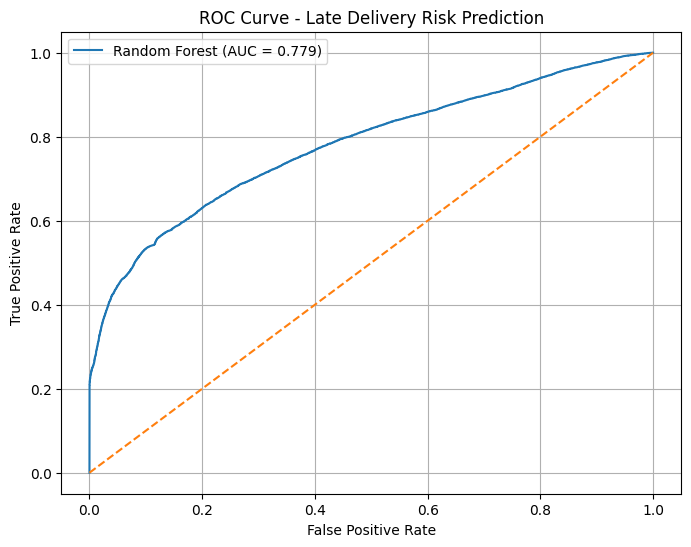

In [10]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"{best_model_name} (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Late Delivery Risk Prediction")

plt.legend()
plt.grid()
plt.show()

In [11]:
def classify_risk(probability):
    if probability < 0.30:
        return "Low Risk"
    elif probability < 0.60:
        return "Medium Risk"
    else:
        return "High Risk"


# Generate predictions for test orders
test_results = X_test.copy()

test_results["Actual Risk"] = y_test
test_results["Late Delivery Probability"] = y_probability

test_results["Risk Category"] = (
    test_results["Late Delivery Probability"]
    .apply(classify_risk)
)

display(test_results.head(10))

print("\nRisk Category Distribution:")
print(test_results["Risk Category"].value_counts())

,Days for shipment (scheduled),Category Id,Department Id,Latitude,Longitude,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Quantity,Sales,...,Customer Segment,Customer State,Department Name,Market,Order Country,Order Region,Shipping Mode,Actual Risk,Late Delivery Probability,Risk Category
69318,4,17,4,41.895119,-87.725189,3.30,0.06,59.99,1,59.99,...,Home Office,IL,Apparel,LATAM,Brasil,South America,Standard Class,0,0.309089,Medium Risk
84032,4,48,7,40.645241,-73.943161,30.00,0.15,199.99,1,199.99,...,Corporate,NY,Fan Shop,Europe,Alemania,Western Europe,Standard Class,0,0.361217,Medium Risk
160369,4,18,4,47.393711,-122.222832,16.90,0.13,129.99,1,129.99,...,Consumer,WA,Apparel,Europe,Francia,Western Europe,Standard Class,0,0.258177,Low Risk
149768,4,46,7,18.247595,-66.370636,7.00,0.07,49.98,2,99.96,...,Corporate,PR,Fan Shop,Europe,Francia,Western Europe,Standard Class,0,0.308040,Medium Risk
107905,4,43,7,33.863297,-117.971626,36.00,0.12,299.98,1,299.98,...,Corporate,CA,Fan Shop,LATAM,México,Central America,Standard Class,1,0.366040,Medium Risk
130552,4,18,4,18.261675,-66.370613,2.60,0.02,129.99,1,129.99,...,Consumer,PR,Apparel,Pacific Asia,Australia,Oceania,Standard Class,0,0.361994,Medium Risk
153004,4,48,7,18.265865,-66.370628,34.00,0.17,199.99,1,199.99,...,Corporate,PR,Fan Shop,Pacific Asia,Australia,Oceania,Standard Class,1,0.308365,Medium Risk
70382,4,24,5,40.726681,-73.979713,12.00,0.12,50.00,2,100.00,...,Corporate,NY,Golf,Europe,Alemania,Western Europe,Standard Class,0,0.366111,Medium Risk
149022,2,18,4,32.535473,-84.954926,7.15,0.06,129.99,1,129.99,...,Home Office,GA,Apparel,Europe,Reino Unido,Northern Europe,Second Class,1,0.752005,High Risk
3231,4,24,5,21.453259,-158.010223,9.00,0.09,50.00,2,100.00,...,Corporate,HI,Golf,USCA,Estados Unidos,US Center,Standard Class,1,0.273129,Low Risk



Risk Category Distribution:
Risk Category
Medium Risk    22031
High Risk      12562
Low Risk        1511
Name: count, dtype: int64


,Feature,Importance
0,num__Days for shipment (scheduled),0.248143
298,cat__Shipping Mode_Standard Class,0.208540
295,cat__Shipping Mode_First Class,0.203914
297,cat__Shipping Mode_Second Class,0.077354
296,cat__Shipping Mode_Same Day,0.024561
3,num__Latitude,0.019833
4,num__Longitude,0.018340
15,cat__Type_TRANSFER,0.016189
10,num__Order Item Total,0.012281
5,num__Order Item Discount,0.011746


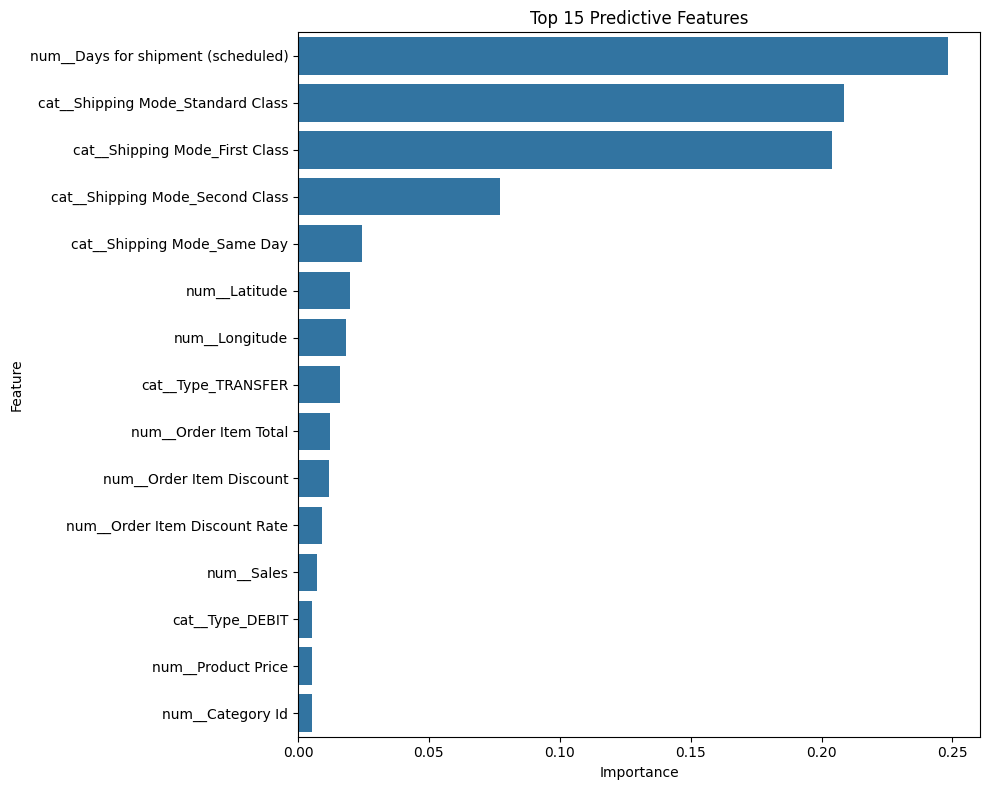

In [12]:
classifier = best_model.named_steps["classifier"]

feature_names = (
    best_model.named_steps["preprocessing"]
    .get_feature_names_out()
)

if hasattr(classifier, "feature_importances_"):

    importance_values = classifier.feature_importances_

elif hasattr(classifier, "coef_"):

    importance_values = np.abs(classifier.coef_[0])

else:
    importance_values = None

if importance_values is not None:

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance_values
    })

    importance_df = importance_df.sort_values(
        by="Importance",
        ascending=False
    )

    display(importance_df.head(20))

    plt.figure(figsize=(10, 8))

    sns.barplot(
        data=importance_df.head(15),
        x="Importance",
        y="Feature"
    )

    plt.title("Top 15 Predictive Features")
    plt.tight_layout()
    plt.show()

In [13]:
import joblib

# Save the complete pipeline, including preprocessing
joblib.dump(
    best_model,
    "best_late_delivery_model.joblib"
)

# Save model comparison
comparison_df.to_csv(
    "model_comparison.csv",
    index=False
)

# Save test predictions
test_results.to_csv(
    "test_predictions.csv",
    index=False
)

# Save selected feature names
joblib.dump(
    feature_columns,
    "feature_columns.joblib"
)

print("All project model files saved successfully!")

All project model files saved successfully!


In [14]:
from google.colab import files

files.download("best_late_delivery_model.joblib")
files.download("model_comparison.csv")
files.download("test_predictions.csv")
files.download("feature_columns.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:

import sys
import sklearn
import numpy
import scipy
import pandas
import joblib
import xgboost

print("Python:", sys.version)
print("Scikit-learn:", sklearn.__version__)
print("NumPy:", numpy.__version__)
print("SciPy:", scipy.__version__)
print("Pandas:", pandas.__version__)
print("Joblib:", joblib.__version__)
print("XGBoost:", xgboost.__version__)


Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Scikit-learn: 1.6.1
NumPy: 2.4.6
SciPy: 1.16.3
Pandas: 2.2.3
Joblib: 1.6.0
XGBoost: 3.4.1
